In [2]:

print("Hello! My CodeAlpha Data Science Project has started.")


Hello! My CodeAlpha Data Science Project has started.


In [3]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:

iris = load_iris(as_frame=True)

X = iris.data
y = iris.target

df = X.copy()
df["species"] = y.map(dict(enumerate(iris.target_names)))

print(df.head())
print("Dataset size:", df.shape)


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
Dataset size: (150, 5)


sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  


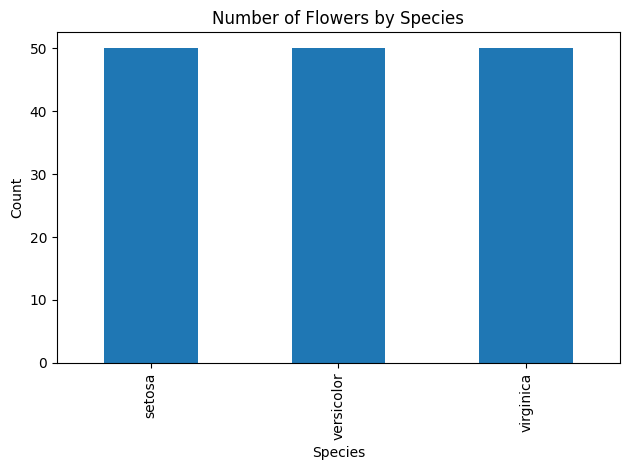

In [5]:
print(df.isnull().sum())
print(df.describe())

df["species"].value_counts().plot(
    kind="bar", title="Number of Flowers by Species"
)
plt.xlabel("Species")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("Model accuracy:", round(accuracy * 100, 2), "%")
print(classification_report(
    y_test, predictions,
    target_names=iris.target_names
))

Model accuracy: 90.0 %
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [7]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

prediction = model.predict(new_flower)[0]

print("Predicted flower species:",
      iris.target_names[prediction])

Predicted flower species: setosa


In [8]:
import joblib

joblib.dump(model, "iris_model.pkl")
print("Model saved successfully.")

Model saved successfully.
